# Homework 8: Final Project Data and EDA
## Jacob Wilson

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Set 1

The following data set is sourced from the Centers for Medicare and Medicaid Services' website (https://www.cms.gov/data-research/statistics-trends-and-reports/national-health-expenditure-data/nhe-fact-sheet). The data contains national health expenditure (NHE) data from 1991 to 2020, with personal healthcare cost estimates (in billions of dollars) organized by state and region (Great Lakes, Rocky Mountains, etc.). Each row corresponds to a state or region within the United States while each column represents a year between 1991 and 2020. This structure is adjusted later in this notebook for the ease of plotting the change in expenditures over this time period. From the website, these expenditure estimates are derived from a combination of costs paid by patients themselves, by private insurance companies, and by public insurance organizations like Medicare and Medicaid.

### Loading data and adjusting column names

In [105]:
df1 = pd.read_csv('C:/Users/jacob/OneDrive/Desktop/DATA 5310/NHEbyState_PersonalCare.csv')

In [106]:
df1.head()

,Table 1: Total All Payers State Estimates by State of Residence (1991 - 2020) - Personal Health Care (Millions of Dollars),Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25,Unnamed: 26,Unnamed: 27,Unnamed: 28,Unnamed: 29,Unnamed: 30,Unnamed: 31
0,Region/state of residence,1991,1992,1993,1994,1995,1996,1997,1998,1999,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,Average\nAnnual %\nGrowth\n(1991-2020)
1,United States,"$672,711","$728,437","$775,720","$817,952","$866,811","$915,029","$966,064","$1,019,653","$1,079,208",...,"$2,346,962","$2,405,667","$2,527,325","$2,674,089","$2,795,322","$2,905,160","$3,021,796","$3,175,230","$3,357,832",5.7%
2,New England,"40,981","43,705","46,452","48,478","52,029","54,760","58,092","62,148","65,048",...,"138,405","141,505","146,939","154,957","161,532","166,153","172,783","180,021","188,974",5.4%
3,Connecticut,"10,915","11,603","12,048","12,695","13,588","14,109","14,933","15,865","16,690",...,"33,181","33,944","35,350","36,941","38,322","39,289","40,671","42,190","44,425",5.0%
4,Maine,"3,139","3,314","3,551","3,699","4,024","4,382","4,739","5,127","5,566",...,"11,625","11,709","12,134","12,747","13,347","13,891","14,674","15,461","16,306",5.8%


In [107]:
df1.columns

Index(['Table 1: Total All Payers State Estimates by State of Residence (1991 - 2020) - Personal Health Care (Millions of Dollars)',
       'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5',
       'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10',
       'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13', 'Unnamed: 14',
       'Unnamed: 15', 'Unnamed: 16', 'Unnamed: 17', 'Unnamed: 18',
       'Unnamed: 19', 'Unnamed: 20', 'Unnamed: 21', 'Unnamed: 22',
       'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25', 'Unnamed: 26',
       'Unnamed: 27', 'Unnamed: 28', 'Unnamed: 29', 'Unnamed: 30',
       'Unnamed: 31'],
      dtype='object')

In [108]:
df1.columns = df1.iloc[0]

In [109]:
df1.head()

,Region/state of residence,1991,1992,1993,1994,1995,1996,1997,1998,1999,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,Average\nAnnual %\nGrowth\n(1991-2020)
0,Region/state of residence,1991,1992,1993,1994,1995,1996,1997,1998,1999,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,Average\nAnnual %\nGrowth\n(1991-2020)
1,United States,"$672,711","$728,437","$775,720","$817,952","$866,811","$915,029","$966,064","$1,019,653","$1,079,208",...,"$2,346,962","$2,405,667","$2,527,325","$2,674,089","$2,795,322","$2,905,160","$3,021,796","$3,175,230","$3,357,832",5.7%
2,New England,"40,981","43,705","46,452","48,478","52,029","54,760","58,092","62,148","65,048",...,"138,405","141,505","146,939","154,957","161,532","166,153","172,783","180,021","188,974",5.4%
3,Connecticut,"10,915","11,603","12,048","12,695","13,588","14,109","14,933","15,865","16,690",...,"33,181","33,944","35,350","36,941","38,322","39,289","40,671","42,190","44,425",5.0%
4,Maine,"3,139","3,314","3,551","3,699","4,024","4,382","4,739","5,127","5,566",...,"11,625","11,709","12,134","12,747","13,347","13,891","14,674","15,461","16,306",5.8%


In [110]:
df1 = df1.drop(index=0)

In [111]:
df1.head()

,Region/state of residence,1991,1992,1993,1994,1995,1996,1997,1998,1999,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,Average\nAnnual %\nGrowth\n(1991-2020)
1,United States,"$672,711","$728,437","$775,720","$817,952","$866,811","$915,029","$966,064","$1,019,653","$1,079,208",...,"$2,346,962","$2,405,667","$2,527,325","$2,674,089","$2,795,322","$2,905,160","$3,021,796","$3,175,230","$3,357,832",5.7%
2,New England,"40,981","43,705","46,452","48,478","52,029","54,760","58,092","62,148","65,048",...,"138,405","141,505","146,939","154,957","161,532","166,153","172,783","180,021","188,974",5.4%
3,Connecticut,"10,915","11,603","12,048","12,695","13,588","14,109","14,933","15,865","16,690",...,"33,181","33,944","35,350","36,941","38,322","39,289","40,671","42,190","44,425",5.0%
4,Maine,"3,139","3,314","3,551","3,699","4,024","4,382","4,739","5,127","5,566",...,"11,625","11,709","12,134","12,747","13,347","13,891","14,674","15,461","16,306",5.8%
5,Massachusetts,"19,939","21,199","22,840","23,740","25,201","26,498","28,014","29,997","30,810",...,"66,322","67,722","70,311","74,842","78,446","80,621","84,112","87,764","91,817",5.4%


In [112]:
df1 = df1.drop(columns = 'Average\nAnnual %\nGrowth\n(1991-2020)')

In [113]:
df1.columns

Index(['Region/state of residence', '1991', '1992', '1993', '1994', '1995',
       '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
       '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013',
       '2014', '2015', '2016', '2017', '2018', '2019', '2020'],
      dtype='object', name=0)

In [114]:
df1.head()

,Region/state of residence,1991,1992,1993,1994,1995,1996,1997,1998,1999,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
1,United States,"$672,711","$728,437","$775,720","$817,952","$866,811","$915,029","$966,064","$1,019,653","$1,079,208",...,"$2,254,675","$2,346,962","$2,405,667","$2,527,325","$2,674,089","$2,795,322","$2,905,160","$3,021,796","$3,175,230","$3,357,832"
2,New England,"40,981","43,705","46,452","48,478","52,029","54,760","58,092","62,148","65,048",...,"134,084","138,405","141,505","146,939","154,957","161,532","166,153","172,783","180,021","188,974"
3,Connecticut,"10,915","11,603","12,048","12,695","13,588","14,109","14,933","15,865","16,690",...,"31,975","33,181","33,944","35,350","36,941","38,322","39,289","40,671","42,190","44,425"
4,Maine,"3,139","3,314","3,551","3,699","4,024","4,382","4,739","5,127","5,566",...,"11,404","11,625","11,709","12,134","12,747","13,347","13,891","14,674","15,461","16,306"
5,Massachusetts,"19,939","21,199","22,840","23,740","25,201","26,498","28,014","29,997","30,810",...,"64,287","66,322","67,722","70,311","74,842","78,446","80,621","84,112","87,764","91,817"


### Dropping null values

In [115]:
df1['Region/state of residence'].value_counts(dropna=False)

Region/state of residence
United States      1
Rocky Mountains    1
Kentucky           1
Louisiana          1
Mississippi        1
                  ..
Nebraska           1
North Dakota       1
South Dakota       1
Southeast          1
NaN                1
Name: count, Length: 63, dtype: int64

In [116]:
df1.tail()

,Region/state of residence,1991,1992,1993,1994,1995,1996,1997,1998,1999,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
59,Oregon,"6,714","7,412","7,904","8,356","8,979","9,486","10,149","11,271","11,991",...,"27,057","27,922","28,953","31,323","33,909","35,607","36,607","38,354","40,623","42,716"
60,Washington,"12,600","13,788","14,442","15,244","16,425","17,078","17,899","19,578","21,273",...,"47,939","50,584","51,245","53,652","56,652","59,104","61,489","64,637","68,253","71,277"
61,NOTE: Numbers may not add to totals shown beca...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
62,SOURCE: Centers for Medicare and Medicaid Serv...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
63,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [117]:
df1 = df1.dropna()

In [118]:
df1.isna().sum()

0
Region/state of residence    0
1991                         0
1992                         0
1993                         0
1994                         0
1995                         0
1996                         0
1997                         0
1998                         0
1999                         0
2000                         0
2001                         0
2002                         0
2003                         0
2004                         0
2005                         0
2006                         0
2007                         0
2008                         0
2009                         0
2010                         0
2011                         0
2012                         0
2013                         0
2014                         0
2015                         0
2016                         0
2017                         0
2018                         0
2019                         0
2020                         0
dtype: int64

In [119]:
df1.columns

Index(['Region/state of residence', '1991', '1992', '1993', '1994', '1995',
       '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
       '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013',
       '2014', '2015', '2016', '2017', '2018', '2019', '2020'],
      dtype='object', name=0)

### Converting All Values to Floats

In [120]:
year_cols = ['1991', '1992', '1993', '1994', '1995',
       '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
       '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013',
       '2014', '2015', '2016', '2017', '2018', '2019', '2020']

In [121]:
df1[year_cols] = (df1[year_cols].astype(str).apply(lambda col: col.str.replace(r'[$,]', '', regex=True)).astype(float))

In [122]:
df1.head()

,Region/state of residence,1991,1992,1993,1994,1995,1996,1997,1998,1999,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
1,United States,672711.0,728437.0,775720.0,817952.0,866811.0,915029.0,966064.0,1019653.0,1079208.0,...,2254675.0,2346962.0,2405667.0,2527325.0,2674089.0,2795322.0,2905160.0,3021796.0,3175230.0,3357832.0
2,New England,40981.0,43705.0,46452.0,48478.0,52029.0,54760.0,58092.0,62148.0,65048.0,...,134084.0,138405.0,141505.0,146939.0,154957.0,161532.0,166153.0,172783.0,180021.0,188974.0
3,Connecticut,10915.0,11603.0,12048.0,12695.0,13588.0,14109.0,14933.0,15865.0,16690.0,...,31975.0,33181.0,33944.0,35350.0,36941.0,38322.0,39289.0,40671.0,42190.0,44425.0
4,Maine,3139.0,3314.0,3551.0,3699.0,4024.0,4382.0,4739.0,5127.0,5566.0,...,11404.0,11625.0,11709.0,12134.0,12747.0,13347.0,13891.0,14674.0,15461.0,16306.0
5,Massachusetts,19939.0,21199.0,22840.0,23740.0,25201.0,26498.0,28014.0,29997.0,30810.0,...,64287.0,66322.0,67722.0,70311.0,74842.0,78446.0,80621.0,84112.0,87764.0,91817.0


In [123]:
df1.describe()

,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
count,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,6.000000e+01,6.000000e+01,6.000000e+01,...,6.000000e+01,6.000000e+01,6.000000e+01,6.000000e+01,6.000000e+01,6.000000e+01,6.000000e+01,6.000000e+01,6.000000e+01,6.000000e+01
mean,33635.550000,36421.866667,38786.000000,40897.550000,43340.550000,45751.483333,48303.250000,5.098267e+04,5.396042e+04,5.785065e+04,...,1.127338e+05,1.173481e+05,1.202834e+05,1.263663e+05,1.337044e+05,1.397661e+05,1.452580e+05,1.510898e+05,1.587615e+05,1.678916e+05
std,90104.677732,97585.425836,103913.735395,109544.854228,116034.146313,122457.010520,129254.942939,1.363613e+05,1.443169e+05,1.546892e+05,...,3.012983e+05,3.136551e+05,3.215341e+05,3.378235e+05,3.575224e+05,3.737755e+05,3.885500e+05,4.042012e+05,4.248212e+05,4.493407e+05
min,1018.000000,1062.000000,1166.000000,1265.000000,1376.000000,1471.000000,1561.000000,1.681000e+03,1.773000e+03,1.959000e+03,...,4.246000e+03,4.469000e+03,4.571000e+03,4.822000e+03,5.074000e+03,5.253000e+03,5.508000e+03,5.667000e+03,5.866000e+03,6.399000e+03
25%,3490.500000,3795.250000,4106.750000,4375.500000,4701.000000,5125.750000,5538.500000,5.875500e+03,6.107000e+03,6.833750e+03,...,1.463500e+04,1.534325e+04,1.577250e+04,1.667975e+04,1.773550e+04,1.867675e+04,1.943175e+04,1.992575e+04,2.088350e+04,2.218525e+04
50%,11056.500000,11916.000000,12580.000000,13302.500000,14071.000000,14723.000000,15633.500000,1.615550e+04,1.702600e+04,1.780400e+04,...,3.596450e+04,3.707800e+04,3.812300e+04,4.033500e+04,4.281600e+04,4.526050e+04,4.751350e+04,4.963250e+04,5.196650e+04,5.403450e+04
75%,26009.250000,27714.500000,29385.500000,31043.500000,33134.250000,35223.250000,36753.750000,3.774300e+04,3.948725e+04,4.218550e+04,...,7.605325e+04,7.894350e+04,8.045025e+04,8.428650e+04,8.852375e+04,9.278350e+04,9.634425e+04,1.003512e+05,1.054490e+05,1.105922e+05
max,672711.000000,728437.000000,775720.000000,817952.000000,866811.000000,915029.000000,966064.000000,1.019653e+06,1.079208e+06,1.157014e+06,...,2.254675e+06,2.346962e+06,2.405667e+06,2.527325e+06,2.674089e+06,2.795322e+06,2.905160e+06,3.021796e+06,3.175230e+06,3.357832e+06


In [124]:
x = np.arange(1991, 2021)
y_wash = np.array(df1.iloc[59])
y_wash = y_wash[1:]
y_wash

array([np.float64(12600.0), np.float64(13788.0), np.float64(14442.0),
       np.float64(15244.0), np.float64(16425.0), np.float64(17078.0),
       np.float64(17899.0), np.float64(19578.0), np.float64(21273.0),
       np.float64(22830.0), np.float64(24951.0), np.float64(27484.0),
       np.float64(29800.0), np.float64(31694.0), np.float64(34177.0),
       np.float64(36660.0), np.float64(39781.0), np.float64(42581.0),
       np.float64(45374.0), np.float64(46608.0), np.float64(47939.0),
       np.float64(50584.0), np.float64(51245.0), np.float64(53652.0),
       np.float64(56652.0), np.float64(59104.0), np.float64(61489.0),
       np.float64(64637.0), np.float64(68253.0), np.float64(71277.0)],
      dtype=object)

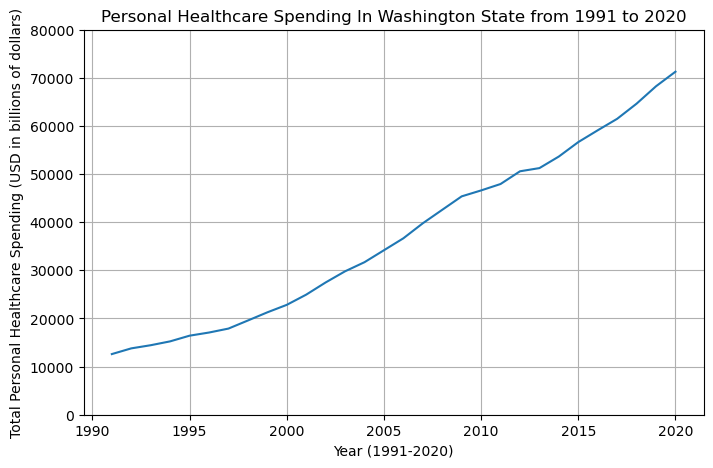

In [296]:
plt.figure(figsize=(8,5))
plt.plot(x,y_wash)
plt.ylim(0, 80000)
plt.xlabel('Year (1991-2020)')
plt.ylabel('Total Personal Healthcare Spending (USD in billions of dollars)')
plt.title('Personal Healthcare Spending In Washington State from 1991 to 2020')
plt.grid()

### Create year column for ease of plotting

In [127]:
df1 = df1.melt(id_vars='Region/state of residence', var_name='Year', value_name='Estimated Total Spending')

In [130]:
df1.head()

,Region/state of residence,Year,Estimated Total Spending
0,United States,1991,672711.0
1,New England,1991,40981.0
2,Connecticut,1991,10915.0
3,Maine,1991,3139.0
4,Massachusetts,1991,19939.0


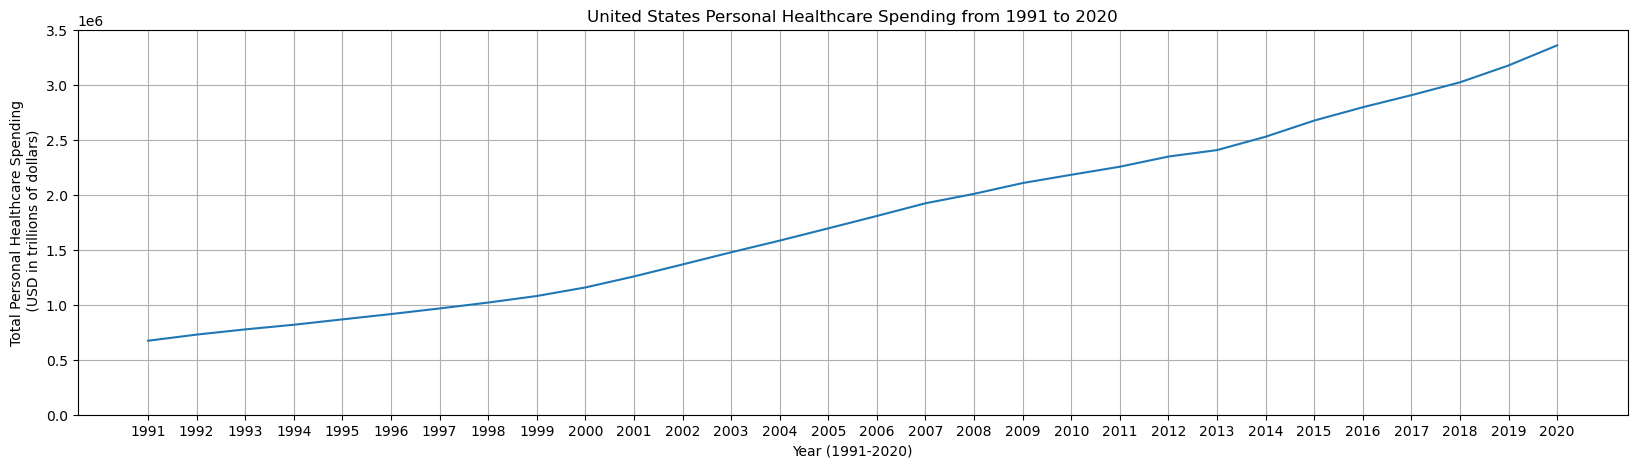

In [303]:
us_totals = df1[df1['Region/state of residence'] == 'United States']

plt.figure(figsize=(20, 5)) 

sns.lineplot(data=us_totals, x = 'Year', y = 'Estimated Total Spending')
plt.ylim(0, 3500000)
plt.xlabel('Year (1991-2020)')
plt.ylabel('Total Personal Healthcare Spending\n (USD in trillions of dollars)')
plt.title('United States Personal Healthcare Spending from 1991 to 2020')
plt.grid()

## Summary

Some interesting patterns worth investigating within this data set would be how the overall increase in personal health care costs net out across each state, and particularly if some states experienced much larger proportional increases in health care costs over others. Additionally it would be worth comparing this at the regional level to see how states compare with their geographical neighbors. This data can stand on its own, though it would be beneficial to compare with similar data from a similar/neighboring nation such as Canada. It could also be worth examining the changes in health care expenditures in United States overseas territories and seeing if they follow a similar pattern to their state counterparts. 

The visualizations I would be most interested in making would be geospatial visualizations comparing the increase in health care costs between each state. This could help to show regional patterns as well assuming that each region's member states follow a similar pattern. I would also like to create some bar charts showing the increase in expenditure over the 30 year period, which would likely be the most effective way to visualize the exponential growth in costs.

## Data Set 2

The following data set is sourced from the Canadian Institute for Health Information (CHIH) (https://www.cihi.ca/en/national-health-expenditure-trends) and covers the total health care expenditures across each province/territory within Canada from 1975-2026. The data set further breaks down this total into the expenditures for physician pay, drugs, public health spending, etc. Additionally, each province/territory possesses its own unique sheet, meaning that they will have to be merged in order for more direct comparison. The final merged dataset has columns for year, province/territory, and estimated total expenditure, with each row representing a single observation for a province/territory in a given year.

### Loading data and adjusting format to match US data

In [245]:
df_nl = pd.read_csv('C:/Users/jacob/OneDrive/Desktop/DATA 5310/nl_canada.csv')
df_pei = pd.read_csv('C:/Users/jacob/OneDrive/Desktop/DATA 5310/pei_canada.csv')
df_ns = pd.read_csv('C:/Users/jacob/OneDrive/Desktop/DATA 5310/ns_canada.csv')
df_nb = pd.read_csv('C:/Users/jacob/OneDrive/Desktop/DATA 5310/nb_canada.csv')
df_que = pd.read_csv('C:/Users/jacob/OneDrive/Desktop/DATA 5310/que_canada.csv')
df_ont = pd.read_csv('C:/Users/jacob/OneDrive/Desktop/DATA 5310/ont_canada.csv')
df_man = pd.read_csv('C:/Users/jacob/OneDrive/Desktop/DATA 5310/man_canada.csv')
df_sask = pd.read_csv('C:/Users/jacob/OneDrive/Desktop/DATA 5310/sask_canada.csv')
df_alta = pd.read_csv('C:/Users/jacob/OneDrive/Desktop/DATA 5310/alta_canada.csv')
df_bc = pd.read_csv('C:/Users/jacob/OneDrive/Desktop/DATA 5310/bc_canada.csv')
df_yt = pd.read_csv('C:/Users/jacob/OneDrive/Desktop/DATA 5310/yt_canada.csv')
df_nwt = pd.read_csv('C:/Users/jacob/OneDrive/Desktop/DATA 5310/nwt_canada.csv')
df_nun = pd.read_csv('C:/Users/jacob/OneDrive/Desktop/DATA 5310/nun_canada.csv')

In [246]:
df_nl.head()

,"There are 3 tables on this tab, each with 2 sub-tables. The first table is called Table D.1.1.1: Total health expenditure by use of funds in millions of current dollars, Newfoundland and Labrador, 1975 to 2026. The sub-table Expenditure by year begins in cell A3. The sub-table Annual growth rate by year begins in cell A57. The second table is called Table D.1.1.2: Percentage distribution of total health expenditure by use of funds, Newfoundland and Labrador, 1975 to 2026. The sub-table Percentage by year begins in cell A115. The sub-table Annual growth rate by year begins in cell A169. The third table is called Table D.1.1.3: Per capita total health expenditure by use of funds in current dollars, Newfoundland and Labrador, 1975 to 2026. The sub-table Expenditure by year begins in cell A227. The sub-table Annual growth rate by year begins in cell A281. Notes and sources can be found after the table in column A.",Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13
0,Table D.1.1.1.a Total health expenditure by u...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Year,Hospitals,Other\nInstitutions,Physicians,Other\nProfessionals,Drugs,Public Health,Administration,Other Health Spending:\nHome and Community\nCa...,Other Health\nSpending:\nNet of HCC,COVID-19\nResponse Funding,Sub-Total,Capital,Total
2,1975,115.9,17.6,26.6,13.4,43.2,7.3,4.4,—,7.3,—,235.8,28.7,264.5
3,1976,129.3,25.7,30.6,14.8,68.0,8.3,5.1,—,8.6,—,290.3,22.5,312.8
4,1977,144.0,33.7,32.4,17.8,97.2,7.3,5.5,—,9.8,—,347.7,15.2,362.9


In [247]:
df_nl.columns = df_nl.iloc[1]

In [248]:
df_nl.head()

1,Year,Hospitals,Other\nInstitutions,Physicians,Other\nProfessionals,Drugs,Public Health,Administration,Other Health Spending:\nHome and Community\nCare (HCC),Other Health\nSpending:\nNet of HCC,COVID-19\nResponse Funding,Sub-Total,Capital,Total
0,Table D.1.1.1.a Total health expenditure by u...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Year,Hospitals,Other\nInstitutions,Physicians,Other\nProfessionals,Drugs,Public Health,Administration,Other Health Spending:\nHome and Community\nCa...,Other Health\nSpending:\nNet of HCC,COVID-19\nResponse Funding,Sub-Total,Capital,Total
2,1975,115.9,17.6,26.6,13.4,43.2,7.3,4.4,—,7.3,—,235.8,28.7,264.5
3,1976,129.3,25.7,30.6,14.8,68.0,8.3,5.1,—,8.6,—,290.3,22.5,312.8
4,1977,144.0,33.7,32.4,17.8,97.2,7.3,5.5,—,9.8,—,347.7,15.2,362.9


In [249]:
df_nl = df_nl.drop(index=[0,1])

In [250]:
df_nl.head()

1,Year,Hospitals,Other\nInstitutions,Physicians,Other\nProfessionals,Drugs,Public Health,Administration,Other Health Spending:\nHome and Community\nCare (HCC),Other Health\nSpending:\nNet of HCC,COVID-19\nResponse Funding,Sub-Total,Capital,Total
2,1975,115.9,17.6,26.6,13.4,43.2,7.3,4.4,—,7.3,—,235.8,28.7,264.5
3,1976,129.3,25.7,30.6,14.8,68.0,8.3,5.1,—,8.6,—,290.3,22.5,312.8
4,1977,144.0,33.7,32.4,17.8,97.2,7.3,5.5,—,9.8,—,347.7,15.2,362.9
5,1978,165.7,40.1,33.9,21.1,113.1,8.8,6.3,—,10.7,—,399.7,13.0,412.7
6,1979,194.4,49.3,37.8,28.8,121.4,10.8,5.0,—,11.8,—,459.1,14.2,473.3


In [251]:
# repeat column adjustment for each province
df_pei.columns = df_pei.iloc[1]
df_pei = df_pei.drop(index=[0,1])

df_ns.columns = df_ns.iloc[1]
df_ns = df_ns.drop(index=[0,1])

df_nb.columns = df_nb.iloc[1]
df_nb = df_nb.drop(index=[0,1])

df_que.columns = df_que.iloc[1]
df_que = df_que.drop(index=[0,1])

df_ont.columns = df_ont.iloc[1]
df_ont = df_ont.drop(index=[0,1])

df_man.columns = df_man.iloc[1]
df_man = df_man.drop(index=[0,1])

df_sask.columns = df_sask.iloc[1]
df_sask = df_sask.drop(index=[0,1])

df_alta.columns = df_alta.iloc[1]
df_alta = df_alta.drop(index=[0,1])

df_bc.columns = df_bc.iloc[1]
df_bc = df_bc.drop(index=[0,1])

df_yt.columns = df_yt.iloc[1]
df_yt = df_yt.drop(index=[0,1])

df_nwt.columns = df_nwt.iloc[1]
df_nwt = df_nwt.drop(index=[0,1])

df_nun.columns = df_nun.iloc[1]
df_nun = df_nun.drop(index=[0,1])

In [252]:
df_nl.tail()

1,Year,Hospitals,Other\nInstitutions,Physicians,Other\nProfessionals,Drugs,Public Health,Administration,Other Health Spending:\nHome and Community\nCare (HCC),Other Health\nSpending:\nNet of HCC,COVID-19\nResponse Funding,Sub-Total,Capital,Total
332,Notes,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
333,f: Forecast\nSub-total equals Total minus Capi...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
334,Source,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
335,"National Health Expenditure Database, 2026, Ca...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
336,End of worksheet (go to Table of contents),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [253]:
df_nl = df_nl.iloc[:52]

In [254]:
df_nl.tail()

1,Year,Hospitals,Other\nInstitutions,Physicians,Other\nProfessionals,Drugs,Public Health,Administration,Other Health Spending:\nHome and Community\nCare (HCC),Other Health\nSpending:\nNet of HCC,COVID-19\nResponse Funding,Sub-Total,Capital,Total
49,2022,"1,536.2",646.9,542.1,321.2,670.4,178.1,139.0,—,737.8,67.3,"4,839.0",428.4,"5,267.4"
50,2023,"1,451.3",687.6,563.9,367.5,684.6,239.7,230.2,—,711.6,—,"4,936.3",535.3,"5,471.6"
51,2024,"1,563.6",744.2,588.4,462.5,743.9,239.9,461.1,—,809.9,—,"5,613.4",427.0,"6,040.4"
52,2025 f,"1,670.1",782.2,684.4,482.5,754.9,271.8,539.7,—,885.2,—,"6,070.8",313.1,"6,384.0"
53,2026 f,"1,916.1",888.4,708.7,492.1,785.1,285.8,607.4,—,979.9,—,"6,663.6",298.0,"6,961.6"


In [255]:
ne_columns = ['Hospitals', 'Other\nInstitutions', 'Physicians',
       'Other\nProfessionals', 'Drugs', 'Public Health', 'Administration',
       'Other Health Spending:\nHome and Community\nCare (HCC)',
       'Other Health\nSpending:\nNet of HCC', 'COVID-19\nResponse Funding',
       'Sub-Total', 'Capital']

In [256]:
df_nl = df_nl.drop(columns=ne_columns)

In [257]:
df_nl.head()

1,Year,Total
2,1975,264.5
3,1976,312.8
4,1977,362.9
5,1978,412.7
6,1979,473.3


In [258]:
df_nl = df_nl.rename(columns={'Total':'Newfoundland'})
df_nl.head()

1,Year,Newfoundland
2,1975,264.5
3,1976,312.8
4,1977,362.9
5,1978,412.7
6,1979,473.3


In [259]:
df_nl = df_nl.T

In [260]:
df_nl.head()

,2,3,4,5,6,7,8,9,10,11,...,44,45,46,47,48,49,50,51,52,53
1,,,,,,,,,,,,,,,,,,,,,
Year,1975,1976,1977,1978,1979,1980,1981,1982,1983,1984,...,2017,2018,2019,2020,2021,2022,2023,2024,2025 f,2026 f
Newfoundland,264.5,312.8,362.9,412.7,473.3,528.4,621.3,701.2,773.7,751.7,...,"4,130.4","4,251.7","4,485.0","4,667.6","5,012.6","5,267.4","5,471.6","6,040.4","6,384.0","6,961.6"


In [261]:
df_nl.columns = df_nl.iloc[0]

In [262]:
df_nl.head()

Year,1975,1976,1977,1978,1979,1980,1981,1982,1983,1984,...,2017,2018,2019,2020,2021,2022,2023,2024,2025 f,2026 f
1,,,,,,,,,,,,,,,,,,,,,
Year,1975,1976,1977,1978,1979,1980,1981,1982,1983,1984,...,2017,2018,2019,2020,2021,2022,2023,2024,2025 f,2026 f
Newfoundland,264.5,312.8,362.9,412.7,473.3,528.4,621.3,701.2,773.7,751.7,...,"4,130.4","4,251.7","4,485.0","4,667.6","5,012.6","5,267.4","5,471.6","6,040.4","6,384.0","6,961.6"


In [263]:
df_nl = df_nl.iloc[1:]

In [264]:
df_nl.head()

Year,1975,1976,1977,1978,1979,1980,1981,1982,1983,1984,...,2017,2018,2019,2020,2021,2022,2023,2024,2025 f,2026 f
1,,,,,,,,,,,,,,,,,,,,,
Newfoundland,264.5,312.8,362.9,412.7,473.3,528.4,621.3,701.2,773.7,751.7,...,"4,130.4","4,251.7","4,485.0","4,667.6","5,012.6","5,267.4","5,471.6","6,040.4","6,384.0","6,961.6"


### Repeat adjustments for each province

In [265]:
df_pei = df_pei.iloc[:52]
df_ns = df_ns.iloc[:52]
df_nb = df_nb.iloc[:52]
df_que = df_que.iloc[:52]
df_ont = df_ont.iloc[:52]
df_man = df_man.iloc[:52]
df_sask = df_sask.iloc[:52]
df_alta = df_alta.iloc[:52]
df_bc = df_bc.iloc[:52]
df_yt = df_yt.iloc[:52]
df_nwt = df_nwt.iloc[:52]
df_nun = df_nun.iloc[:52]

In [266]:
df_pei = df_pei.drop(columns=ne_columns)
df_ns = df_ns.drop(columns=ne_columns)
df_nb = df_nb.drop(columns=ne_columns)
df_que = df_que.drop(columns=ne_columns)
df_ont = df_ont.drop(columns=ne_columns)
df_man = df_man.drop(columns=ne_columns)
df_sask = df_sask.drop(columns=ne_columns)
df_alta = df_alta.drop(columns=ne_columns)
df_bc = df_bc.drop(columns=ne_columns)
df_yt = df_yt.drop(columns=ne_columns)
df_nwt = df_nwt.drop(columns=ne_columns)
df_nun = df_nun.drop(columns=ne_columns)

In [267]:
df_pei = df_pei.rename(columns={'Total':'Prince Edward Island'})
df_ns = df_ns.rename(columns={'Total':'Nova Scotia'})
df_nb = df_nb.rename(columns={'Total':'New Brunswick'})
df_que = df_que.rename(columns={'Total':'Quebec'})
df_ont = df_ont.rename(columns={'Total':'Ontario'})
df_man = df_man.rename(columns={'Total':'Manitoba'})
df_sask = df_sask.rename(columns={'Total':'Saskatchewan'})
df_alta = df_alta.rename(columns={'Total':'Alberta'})
df_bc = df_bc.rename(columns={'Total':'British Columbia'})
df_yt = df_yt.rename(columns={'Total':'Yukon Teritory'})
df_nwt = df_nwt.rename(columns={'Total':'Northwest Territories'})
df_nun = df_nun.rename(columns={'Total':'Nunavut'})

In [268]:
df_pei = df_pei.T
df_ns = df_ns.T
df_nb = df_nb.T
df_que = df_que.T
df_ont = df_ont.T
df_man = df_man.T
df_sask = df_sask.T
df_alta = df_alta.T
df_bc = df_bc.T
df_yt = df_yt.T
df_nwt = df_nwt.T
df_nun = df_nun.T

In [269]:
df_pei.columns = df_pei.iloc[0]
df_ns.columns = df_ns.iloc[0]
df_nb.columns = df_nb.iloc[0]
df_que.columns = df_que.iloc[0]
df_ont.columns = df_ont.iloc[0]
df_man.columns = df_man.iloc[0]
df_sask.columns = df_sask.iloc[0]
df_alta.columns = df_alta.iloc[0]
df_bc.columns = df_bc.iloc[0]
df_yt.columns = df_yt.iloc[0]
df_nwt.columns = df_nwt.iloc[0]
df_nun.columns = df_nun.iloc[0]

In [270]:
df_pei = df_pei.iloc[1:]
df_ns = df_ns.iloc[1:]
df_nb = df_nb.iloc[1:]
df_que = df_que.iloc[1:]
df_ont = df_ont.iloc[1:]
df_man = df_man.iloc[1:]
df_sask = df_sask.iloc[1:]
df_alta = df_alta.iloc[1:]
df_bc = df_bc.iloc[1:]
df_yt = df_yt.iloc[1:]
df_nwt = df_nwt.iloc[1:]
df_nun = df_nun.iloc[1:]

In [271]:
df_canada = pd.concat([df_nl, df_pei, df_ns, df_nb, df_que, df_ont, df_man, df_sask, df_alta, df_bc, df_yt, df_nwt, df_nun], ignore_index=False)

In [272]:
df_canada.head()

Year,1975,1976,1977,1978,1979,1980,1981,1982,1983,1984,...,2017,2018,2019,2020,2021,2022,2023,2024,2025 f,2026 f
1,,,,,,,,,,,,,,,,,,,,,
Newfoundland,264.5,312.8,362.9,412.7,473.3,528.4,621.3,701.2,773.7,751.7,...,"4,130.4","4,251.7","4,485.0","4,667.6","5,012.6","5,267.4","5,471.6","6,040.4","6,384.0","6,961.6"
Prince Edward Island,59.2,62.9,68.7,79.5,96.6,122.3,136.4,152.4,164.5,171.0,...,"1,062.7","1,121.0","1,172.8","1,254.8","1,350.6","1,428.5","1,570.0","1,846.8","2,130.1","2,307.2"
Nova Scotia,382.5,442.2,469.1,512.5,573.0,657.2,788.8,919.1,"1,004.9","1,125.3",...,"6,954.2","7,190.1","7,570.9","8,273.8","9,003.0","9,702.3","10,772.9","11,984.7","13,167.7","13,922.3"
New Brunswick,277.5,321.9,358.9,404.7,470.0,562.5,681.2,819.3,894.6,975.1,...,"5,266.3","5,354.4","5,541.4","6,037.0","6,445.3","6,820.4","7,522.4","8,191.9","8,737.7","9,186.8"
Quebec,"3,378.8","3,875.2","4,200.7","4,666.6","5,149.6","5,886.5","6,887.8","7,890.5","8,675.3","9,313.7",...,"52,732.1","55,499.1","57,877.3","70,383.5","76,463.8","75,904.5","78,730.8","83,443.7","86,458.3","89,295.9"


In [273]:
df_canada.tail()

Year,1975,1976,1977,1978,1979,1980,1981,1982,1983,1984,...,2017,2018,2019,2020,2021,2022,2023,2024,2025 f,2026 f
1,,,,,,,,,,,,,,,,,,,,,
Alberta,992.3,"1,158.9","1,272.1","1,465.4","1,781.0","2,153.1","2,623.7","3,351.7","3,622.1","3,764.2",...,"32,450.0","33,762.8","34,559.4","37,143.9","39,110.0","40,276.4","43,393.3","46,695.2","50,221.1","52,965.0"
British Columbia,"1,383.4","1,628.3","1,831.8","2,044.4","2,288.6","2,880.0","3,430.4","3,870.2","4,155.7","4,428.9",...,"31,849.4","34,256.1","36,672.8","40,617.3","44,633.9","46,626.5","51,729.1","57,189.8","61,081.5","63,357.4"
Yukon Teritory,15.9,18.1,18.5,21.3,23.9,26.1,28.2,37.1,38.0,37.9,...,506.7,509.3,536.0,603.0,663.4,710.9,812.0,910.0,960.9,"1,009.3"
Northwest Territories,35.1,39.0,49.3,56.5,59.0,61.1,73.8,110.4,123.5,125.8,...,689.9,758.3,802.6,878.4,923.2,"1,004.4","1,116.2","1,215.3","1,276.1","1,311.4"
Nunavut,—,—,—,—,—,—,—,—,—,—,...,635.0,692.4,766.5,850.6,853.3,902.7,"1,112.8","1,309.9","1,383.2","1,419.1"


In [274]:
df_canada

Year,1975,1976,1977,1978,1979,1980,1981,1982,1983,1984,...,2017,2018,2019,2020,2021,2022,2023,2024,2025 f,2026 f
1,,,,,,,,,,,,,,,,,,,,,
Newfoundland,264.5,312.8,362.9,412.7,473.3,528.4,621.3,701.2,773.7,751.7,...,"4,130.4","4,251.7","4,485.0","4,667.6","5,012.6","5,267.4","5,471.6","6,040.4","6,384.0","6,961.6"
Prince Edward Island,59.2,62.9,68.7,79.5,96.6,122.3,136.4,152.4,164.5,171.0,...,"1,062.7","1,121.0","1,172.8","1,254.8","1,350.6","1,428.5","1,570.0","1,846.8","2,130.1","2,307.2"
Nova Scotia,382.5,442.2,469.1,512.5,573.0,657.2,788.8,919.1,"1,004.9","1,125.3",...,"6,954.2","7,190.1","7,570.9","8,273.8","9,003.0","9,702.3","10,772.9","11,984.7","13,167.7","13,922.3"
New Brunswick,277.5,321.9,358.9,404.7,470.0,562.5,681.2,819.3,894.6,975.1,...,"5,266.3","5,354.4","5,541.4","6,037.0","6,445.3","6,820.4","7,522.4","8,191.9","8,737.7","9,186.8"
Quebec,"3,378.8","3,875.2","4,200.7","4,666.6","5,149.6","5,886.5","6,887.8","7,890.5","8,675.3","9,313.7",...,"52,732.1","55,499.1","57,877.3","70,383.5","76,463.8","75,904.5","78,730.8","83,443.7","86,458.3","89,295.9"
Ontario,"4,422.8","5,040.8","5,524.6","6,071.9","6,728.0","7,634.1","8,903.0","10,445.2","11,850.0","13,086.0",...,"93,499.0","96,018.4","100,301.9","112,650.2","122,575.8","123,685.8","134,237.1","145,608.7","150,867.3","159,862.9"
Manitoba,546.3,629.4,706.0,749.0,823.3,971.4,"1,153.2","1,332.1","1,478.6","1,592.0",...,"9,733.8","9,904.5","10,255.0","11,286.6","12,093.6","12,418.4","13,871.0","15,299.0","16,843.1","17,445.2"
Saskatchewan,441.2,520.3,587.4,622.4,703.5,815.7,949.0,"1,130.0","1,257.6","1,371.3",...,"8,610.9","8,811.7","9,253.8","10,012.2","10,714.2","10,959.8","11,844.0","13,079.7","13,599.1","14,075.4"
Alberta,992.3,"1,158.9","1,272.1","1,465.4","1,781.0","2,153.1","2,623.7","3,351.7","3,622.1","3,764.2",...,"32,450.0","33,762.8","34,559.4","37,143.9","39,110.0","40,276.4","43,393.3","46,695.2","50,221.1","52,965.0"


### Create year column for ease of plotting

In [275]:
df_canada.index.name = 'Province/Territory'
df_canada.head()

Year,1975,1976,1977,1978,1979,1980,1981,1982,1983,1984,...,2017,2018,2019,2020,2021,2022,2023,2024,2025 f,2026 f
Province/Territory,,,,,,,,,,,,,,,,,,,,,
Newfoundland,264.5,312.8,362.9,412.7,473.3,528.4,621.3,701.2,773.7,751.7,...,"4,130.4","4,251.7","4,485.0","4,667.6","5,012.6","5,267.4","5,471.6","6,040.4","6,384.0","6,961.6"
Prince Edward Island,59.2,62.9,68.7,79.5,96.6,122.3,136.4,152.4,164.5,171.0,...,"1,062.7","1,121.0","1,172.8","1,254.8","1,350.6","1,428.5","1,570.0","1,846.8","2,130.1","2,307.2"
Nova Scotia,382.5,442.2,469.1,512.5,573.0,657.2,788.8,919.1,"1,004.9","1,125.3",...,"6,954.2","7,190.1","7,570.9","8,273.8","9,003.0","9,702.3","10,772.9","11,984.7","13,167.7","13,922.3"
New Brunswick,277.5,321.9,358.9,404.7,470.0,562.5,681.2,819.3,894.6,975.1,...,"5,266.3","5,354.4","5,541.4","6,037.0","6,445.3","6,820.4","7,522.4","8,191.9","8,737.7","9,186.8"
Quebec,"3,378.8","3,875.2","4,200.7","4,666.6","5,149.6","5,886.5","6,887.8","7,890.5","8,675.3","9,313.7",...,"52,732.1","55,499.1","57,877.3","70,383.5","76,463.8","75,904.5","78,730.8","83,443.7","86,458.3","89,295.9"


In [276]:
df_canada['Province/Territory'] = df_canada.index
df_canada.head()

Year,1975,1976,1977,1978,1979,1980,1981,1982,1983,1984,...,2018,2019,2020,2021,2022,2023,2024,2025 f,2026 f,Province/Territory
Province/Territory,,,,,,,,,,,,,,,,,,,,,
Newfoundland,264.5,312.8,362.9,412.7,473.3,528.4,621.3,701.2,773.7,751.7,...,"4,251.7","4,485.0","4,667.6","5,012.6","5,267.4","5,471.6","6,040.4","6,384.0","6,961.6",Newfoundland
Prince Edward Island,59.2,62.9,68.7,79.5,96.6,122.3,136.4,152.4,164.5,171.0,...,"1,121.0","1,172.8","1,254.8","1,350.6","1,428.5","1,570.0","1,846.8","2,130.1","2,307.2",Prince Edward Island
Nova Scotia,382.5,442.2,469.1,512.5,573.0,657.2,788.8,919.1,"1,004.9","1,125.3",...,"7,190.1","7,570.9","8,273.8","9,003.0","9,702.3","10,772.9","11,984.7","13,167.7","13,922.3",Nova Scotia
New Brunswick,277.5,321.9,358.9,404.7,470.0,562.5,681.2,819.3,894.6,975.1,...,"5,354.4","5,541.4","6,037.0","6,445.3","6,820.4","7,522.4","8,191.9","8,737.7","9,186.8",New Brunswick
Quebec,"3,378.8","3,875.2","4,200.7","4,666.6","5,149.6","5,886.5","6,887.8","7,890.5","8,675.3","9,313.7",...,"55,499.1","57,877.3","70,383.5","76,463.8","75,904.5","78,730.8","83,443.7","86,458.3","89,295.9",Quebec


In [277]:
df_canada = df_canada.melt(id_vars='Province/Territory', var_name='Year', value_name='Estimated Total Spending')
df_canada.head()

,Province/Territory,Year,Estimated Total Spending
0,Newfoundland,1975,264.5
1,Prince Edward Island,1975,59.2
2,Nova Scotia,1975,382.5
3,New Brunswick,1975,277.5
4,Quebec,1975,"3,378.8"


In [278]:
df_canada.tail()

,Province/Territory,Year,Estimated Total Spending
671,Alberta,2026 f,"52,965.0"
672,British Columbia,2026 f,"63,357.4"
673,Yukon Teritory,2026 f,"1,009.3"
674,Northwest Territories,2026 f,"1,311.4"
675,Nunavut,2026 f,"1,419.1"


### Clean up numerical values 

In [279]:
empty_values = df_canada[df_canada['Estimated Total Spending'] == '—']
empty_values

,Province/Territory,Year,Estimated Total Spending
12,Nunavut,1975,—
25,Nunavut,1976,—
38,Nunavut,1977,—
51,Nunavut,1978,—
64,Nunavut,1979,—
77,Nunavut,1980,—
90,Nunavut,1981,—
103,Nunavut,1982,—
116,Nunavut,1983,—
129,Nunavut,1984,—


In [280]:
df_canada = df_canada[df_canada['Estimated Total Spending'] != '—']

In [281]:
df_canada['Estimated Total Spending'] = df_canada['Estimated Total Spending'].str.replace(',', '').astype(float)

In [282]:
df_canada.tail()

,Province/Territory,Year,Estimated Total Spending
671,Alberta,2026 f,52965.0
672,British Columbia,2026 f,63357.4
673,Yukon Teritory,2026 f,1009.3
674,Northwest Territories,2026 f,1311.4
675,Nunavut,2026 f,1419.1


In [283]:
df_canada['Year'] = df_canada['Year'].str.replace('f', '').astype(int)

In [284]:
df_canada.tail()

,Province/Territory,Year,Estimated Total Spending
671,Alberta,2026,52965.0
672,British Columbia,2026,63357.4
673,Yukon Teritory,2026,1009.3
674,Northwest Territories,2026,1311.4
675,Nunavut,2026,1419.1


In [317]:
df_canada['Estimated Total Spending'].describe()

count       652.000000
mean      11412.845706
std       21839.426069
min          15.900000
25%         654.300000
50%        2784.800000
75%       10017.125000
max      159862.900000
Name: Estimated Total Spending, dtype: float64

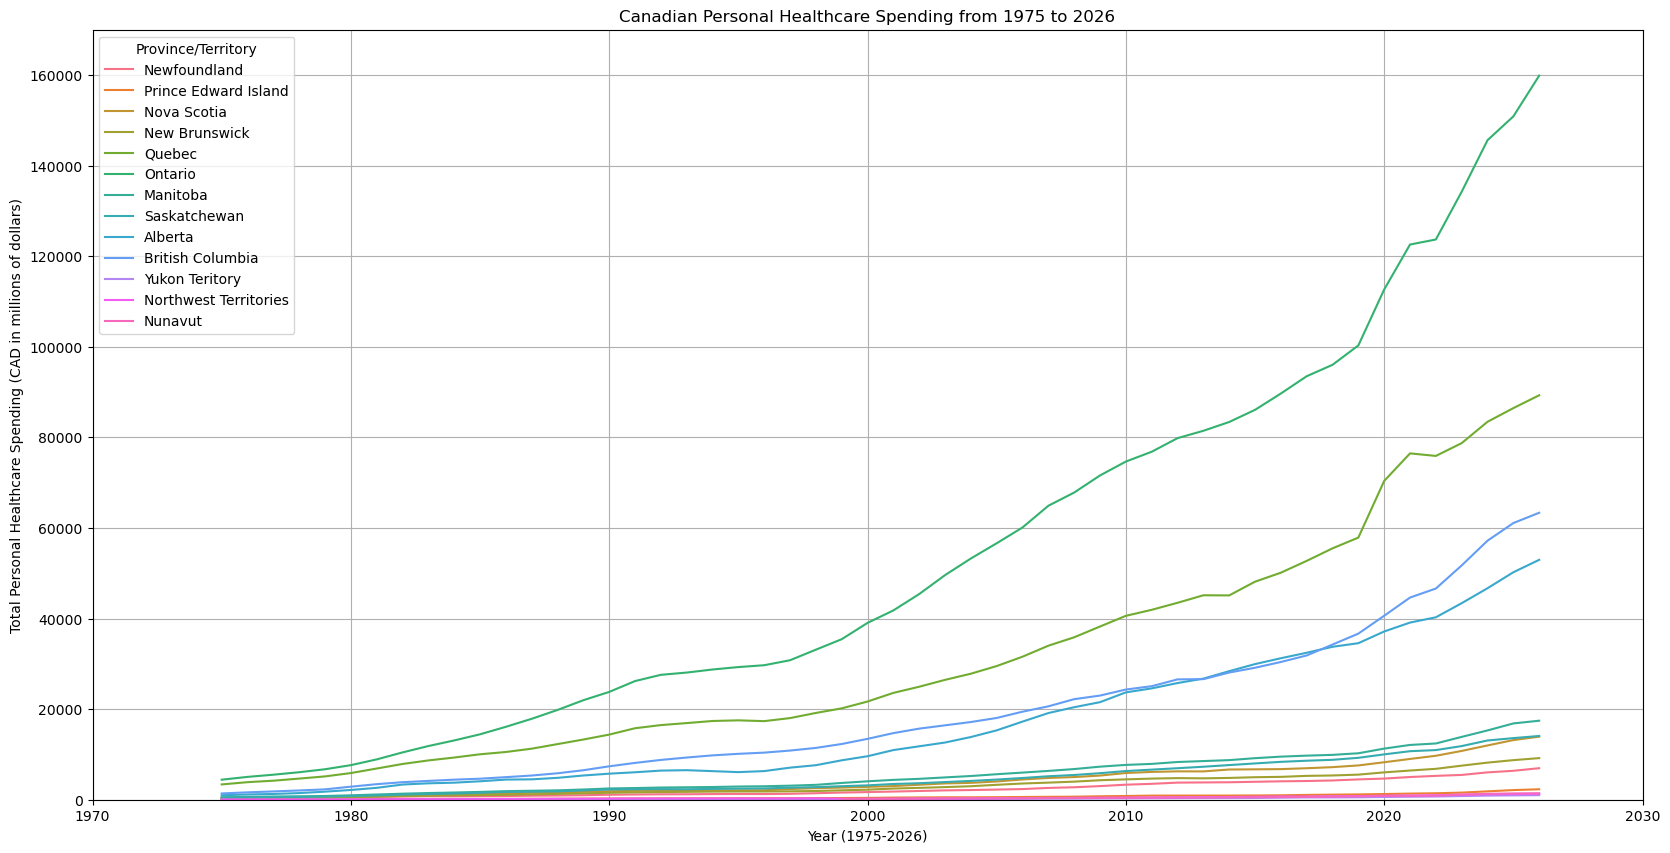

In [318]:
plt.figure(figsize=(20, 10)) 

sns.lineplot(data=df_canada, x = 'Year', y = 'Estimated Total Spending', hue='Province/Territory')
plt.xlim(1970, 2030)
plt.ylim(0, 170000)
plt.xlabel('Year (1975-2026)')
plt.ylabel('Total Personal Healthcare Spending (CAD in millions of dollars)')
plt.title('Canadian Personal Healthcare Spending from 1975 to 2026')
plt.grid()

### Summary

Some interesting patterns worth investigating for the Canadian data set would be the rate of increase in cost across each province, as well as how provinces compare to territories which possess different constitutional status. This data likewise can stand on its own, though it could help to compare to other nations such as the US or other OECD nations with a similar national health care system.

The visualizations I would like to make here would again be geospatial visualizations comparing the increase in health care costs between each province/territory. 
It would also be beneficial to develop bar charts breaking down the total cost for a given year or several years based on specific domains (hospitals, drugs, public health spending, etc.).